***Outlier Detection, PCA & Data Augmentation***

In [1]:
!pip -q install imbalanced-learn
!apt-get -qq update
!apt-get -qq install -y texlive-latex-extra texlive-fonts-recommended cm-super dvipng

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Extracting templates from packages: 100%
Preconfiguring packages ...
Selecting previously unselected package fonts-droid-fallback.
(Reading database ... 122806 files and directories currently installed.)
Preparing to unpack .../00-fonts-droid-fallback_1%3a6.0.1r16-1.1build1_all.deb ...
Unpacking fonts-droid-fallback (1:6.0.1r16-1.1build1) ...
Selecting previously unselected package fonts-lato.
Preparing to unpack .../01-fonts-lato_2.015-1_all.deb ...
Unpacking fonts-lato (2.015-1) ...
Selecting previously unselected package poppler-data.
Preparing to unpack .../02-poppler-data_0.4.12-1_all.deb ...
Unpacking poppler-data (0.4.12-1) ...
Selecting previously unselected package at-spi2-common.
Preparing to unpack .../03-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) .

In [3]:
import pandas as pd, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt, os
plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "serif"
os.makedirs("figures", exist_ok=True)

df = pd.read_csv("preprocessed_data.csv")
result_order = ["Extinguished early", "Partially burned", "Completely burned"]
df["fire_result"] = pd.Categorical(df["fire_result"], categories=result_order, ordered=True)

num = ["arrival_min", "water_m3", "foam_kg", "dry_powder_kg",
       "human_deaths", "human_injured", "animal_deaths"]
print(df.shape)
print("Missing values:", df.isna().sum().sum())

(31845, 18)
Missing values: 0


***9. Outlier Detection***

In [5]:
# 9a. Univariate detection: IQR rule and z-score rule
q1, q3 = df[num].quantile(0.25), df[num].quantile(0.75)
iqr = q3 - q1
iqr_out = (df[num] < q1 - 1.5 * iqr) | (df[num] > q3 + 1.5 * iqr)
z = (df[num] - df[num].mean()) / df[num].std(ddof=0)
z_out = z.abs() > 3

uni = pd.DataFrame({"non_zero_%": (df[num] > 0).mean() * 100,
                    "upper_fence": q3 + 1.5 * iqr,
                    "IQR_outliers": iqr_out.sum(),
                    "z>3_outliers": z_out.sum(),
                    "max": df[num].max()})
print(uni.round(2))
print("\nRecords flagged by IQR:", iqr_out.any(axis=1).sum())
print("Records flagged by |z| > 3:", z_out.any(axis=1).sum())

               non_zero_%  upper_fence  IQR_outliers  z>3_outliers      max
arrival_min        100.00        11.50          2729           417    260.0
water_m3            87.43         7.05          2840            21  40000.0
foam_kg              2.00         0.00           637           114   6000.0
dry_powder_kg        2.48         0.00           791           268    120.0
human_deaths         0.15         0.00            48            48      5.0
human_injured        0.98         0.00           313           313     13.0
animal_deaths        0.36         0.00           114             8   6000.0

Records flagged by IQR: 6353
Records flagged by |z| > 3: 1139


In [6]:
# 9b. are the extreme values errors or real events? Largest values of each attribute
cols = ["fire_type", "fire_result", "water_m3", "foam_kg", "animal_deaths", "district", "month", "year"]
for c in ["water_m3", "foam_kg", "animal_deaths"]:
    print(f"\nLargest {c}:")
    print(df.nlargest(5, c)[cols].to_string())


Largest water_m3:
            fire_type         fire_result  water_m3  foam_kg  animal_deaths     district  month  year
23619  Forest/nursery    Partially burned   40000.0    500.0          166.0     MENDERES      6  2025
23662  Forest/nursery    Partially burned   30000.0   1000.0            0.0  SEFERİHİSAR      6  2025
14421         Garbage  Extinguished early   20000.0      0.0            0.0    KARŞIYAKA     11  2024
10734     Olive grove    Partially burned   10000.0    100.0            3.0     BAYINDIR      8  2024
24016  Forest/nursery   Completely burned   10000.0      0.0         1169.0       ÖDEMİŞ      7  2025

Largest foam_kg:
              fire_type        fire_result  water_m3  foam_kg  animal_deaths   district  month  year
11107         Workplace  Completely burned     400.0   6000.0            0.0  KARŞIYAKA      8  2024
5816   Factory/workshop   Partially burned     500.0   3000.0            0.0      ÇİĞLİ      6  2024
14494  Factory/workshop  Completely burned     3

In [7]:
# 9c. Plausibility check: early-extinguished fires with extreme water use
p999 = df["water_m3"].quantile(0.999)
suspect = (df["fire_result"] == "Extinguished early") & (df["water_m3"] > p999)
print(f"99.9th percentile of water: {p999:.0f} m3")
print("Suspicious records:", suspect.sum())
print(df.loc[suspect, cols].sort_values("water_m3", ascending=False).to_string())

print("\nWater used by fire result:")
print(df.groupby("fire_result", observed=True)["water_m3"].describe(percentiles=[0.5, 0.99])[["50%", "99%", "max"]])

99.9th percentile of water: 600 m3
Suspicious records: 5
              fire_type         fire_result  water_m3  foam_kg  animal_deaths    district  month  year
14421           Garbage  Extinguished early   20000.0      0.0            0.0   KARŞIYAKA     11  2024
25801           Garbage  Extinguished early    3700.0      0.0            0.0        BUCA      7  2025
25239  Factory/workshop  Extinguished early    3000.0      0.0            0.0     TORBALI      7  2025
19560           Garbage  Extinguished early    1000.0      0.0            0.0  KARABAĞLAR      4  2025
14817           Garbage  Extinguished early     800.0      0.0            0.0   KARŞIYAKA     11  2024

Water used by fire result:
                    50%    99%      max
fire_result                            
Extinguished early  1.0   35.0  20000.0
Partially burned    5.0  500.0  40000.0
Completely burned   3.5  883.5  10000.0


In [8]:
# 9d. Replace implausible values with the fire-type median (same as imputation step)
df_out = df.copy()
df_out.loc[suspect, "water_m3"] = np.nan
df_out["water_m3"] = df_out["water_m3"].fillna(df_out.groupby("fire_type")["water_m3"].transform("median"))

print(pd.DataFrame({"fire_type": df.loc[suspect, "fire_type"],
                    "before": df.loc[suspect, "water_m3"],
                    "after": df_out.loc[suspect, "water_m3"]}))
print("\nMissing values:", df_out.isna().sum().sum())
print("Records:", len(df_out))

              fire_type   before  after
14421           Garbage  20000.0    1.0
14817           Garbage    800.0    1.0
19560           Garbage   1000.0    1.0
25239  Factory/workshop   3000.0    2.0
25801           Garbage   3700.0    1.0

Missing values: 0
Records: 31845


In [9]:
# 9e. Multivariate detection: Isolation Forest on log-transformed, standardized attributes
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

X_iso = StandardScaler().fit_transform(np.log1p(df_out[num]))
iso = IsolationForest(contamination=0.01, random_state=42)
df_out["iso_outlier"] = iso.fit_predict(X_iso) == -1
print("Isolation Forest outliers:", df_out["iso_outlier"].sum())

share = pd.DataFrame({
    "All fires": df_out["fire_result"].value_counts(normalize=True, sort=False) * 100,
    "Outliers": df_out.loc[df_out["iso_outlier"], "fire_result"].value_counts(normalize=True, sort=False) * 100})
print("\nFire result (%):\n", share.round(1))
print("\nMost common fire types among outliers:")
print(df_out.loc[df_out["iso_outlier"], "fire_type"].value_counts().head(5))
print("\nMedian water / foam (outliers = True):")
print(df_out.groupby("iso_outlier")[["water_m3", "foam_kg"]].median())

Isolation Forest outliers: 318

Fire result (%):
                     All fires  Outliers
fire_result                            
Extinguished early       92.2      42.5
Partially burned          4.7      31.1
Completely burned         3.2      26.4

Most common fire types among outliers:
fire_type
Building            70
Factory/workshop    54
Workplace           41
Vehicle             23
Garbage             20
Name: count, dtype: int64

Median water / foam (outliers = True):
             water_m3  foam_kg
iso_outlier                   
False             1.0      0.0
True             30.0     67.5


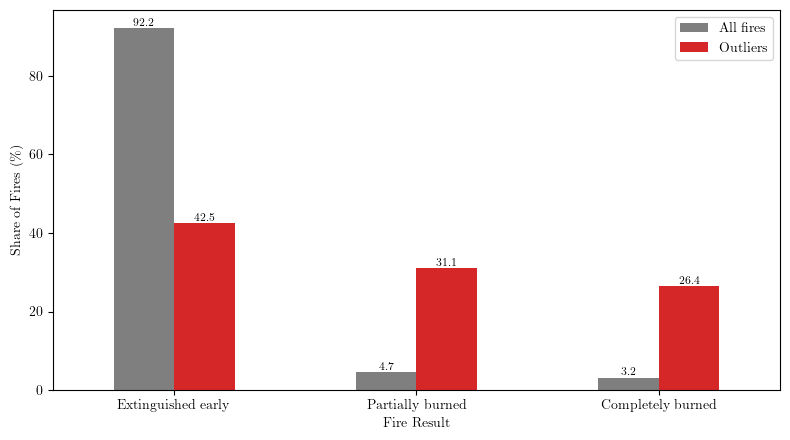

In [10]:
# Figure: fire result of all fires vs. Isolation Forest outliers
ax = share.plot(kind="bar", figsize=(8, 4.5), rot=0, color=["tab:gray", "tab:red"])
ax.set_xlabel("Fire Result"); ax.set_ylabel(r"Share of Fires (\%)")
for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=8)
plt.tight_layout()
plt.savefig("figures/outlier_fire_result.png", dpi=300, bbox_inches="tight")
plt.show()


In [20]:
# LaTeX (pgfplots) version of the outlier figure, same function as in preprocessing.ipynb
def bars_to_latex(data, path, xlabel, ylabel, colors, decimals=1):
    cats = [str(c) for c in data.index]
    ymax = float(np.ceil(data.values.max() * 1.15))
    L = ["{%", r"\begin{tikzpicture}", r"\begin{axis}[",
         r"  width=\columnwidth, height=0.62\columnwidth,",
         rf"  ybar, bar width=12pt, ymin=0, ymax={ymax:g},",
         r"  symbolic x coords={" + ",".join(cats) + "}, xtick=data,",
         r"  enlarge x limits=0.25,",
         r"  xlabel={" + xlabel + "}, ylabel={" + ylabel + "},",
         r"  tick label style={font=\scriptsize}, label style={font=\small},",
         r"  nodes near coords={\pgfmathprintnumber[fixed,fixed zerofill,precision="
             + str(decimals) + r"]{\pgfplotspointmeta}},",
         r"  every node near coord/.append style={font=\tiny},",
         r"  legend style={at={(0.98,0.98)}, anchor=north east, font=\scriptsize},",
         r"  legend cell align=left,",
         "]"]
    for col, c in zip(data.columns, colors):
        r, g, b = [int(round(x * 255)) for x in mpl.colors.to_rgb(c)]
        coords = " ".join(f"({cat},{v:.{decimals}f})" for cat, v in zip(cats, data[col]))
        L.append(rf"\addplot[fill={{rgb,255:red,{r};green,{g};blue,{b}}}, draw=none] coordinates {{{coords}}};")
        L.append(r"\addlegendentry{" + str(col) + "}")
    L += [r"\end{axis}", r"\end{tikzpicture}%", "}"]
    with open(path, "w", encoding="utf-8") as f:
        f.write("\n".join(L))
    print("Saved:", path)

bars_to_latex(share, "figures/outlier_fire_result.tex", xlabel="Fire Result",
              ylabel=r"Share of Fires (\%)", colors=["tab:gray", "tab:red"])

Saved: figures/outlier_fire_result.tex


Isolation Forest looks at all 7 attributes together and isolates records that are far from the rest using random splits. With 1% contamination it flags 318 fires. 57.5% of them were partially or completely burned, compared with 7.8% of all fires, and most are building, factory and workplace fires. So these outliers are the most serious fires, not errors. We did not remove them, we only marked them with the iso_outlier column.

***10. Principal Component Analysis (PCA)***

In [11]:
# 10a. PCA on two versions of the 7 attributes: z-score and log1p + z-score
from sklearn.decomposition import PCA

X_z = StandardScaler().fit_transform(df_out[num])
X_log = StandardScaler().fit_transform(np.log1p(df_out[num]))
pca_z, pca_log = PCA().fit(X_z), PCA().fit(X_log)

pcs = [f"PC{i}" for i in range(1, 8)]
evr = pd.DataFrame({"z-score": pca_z.explained_variance_ratio_ * 100,
                    "log + z-score": pca_log.explained_variance_ratio_ * 100}, index=pcs)
print("Explained variance (%):\n", evr.round(1))
print("\nCumulative (%):\n", evr.cumsum().round(1))

Explained variance (%):
      z-score  log + z-score
PC1     16.8           20.2
PC2     15.1           15.8
PC3     14.6           14.5
PC4     14.3           14.0
PC5     14.1           13.7
PC6     13.1           12.8
PC7     12.0            9.0

Cumulative (%):
      z-score  log + z-score
PC1     16.8           20.2
PC2     31.9           36.0
PC3     46.4           50.5
PC4     60.7           64.5
PC5     74.8           78.1
PC6     88.0           91.0
PC7    100.0          100.0


In [12]:
# 10b. Loadings of the first three components (log version)
load = pd.DataFrame(pca_log.components_[:3].T, index=num, columns=pcs[:3])
print(load.round(2))

                PC1   PC2   PC3
arrival_min    0.41 -0.42 -0.17
water_m3       0.67 -0.14  0.09
foam_kg        0.47  0.21  0.54
dry_powder_kg -0.15  0.34  0.56
human_deaths   0.15  0.50 -0.55
human_injured  0.16  0.60 -0.09
animal_deaths  0.28  0.17 -0.21


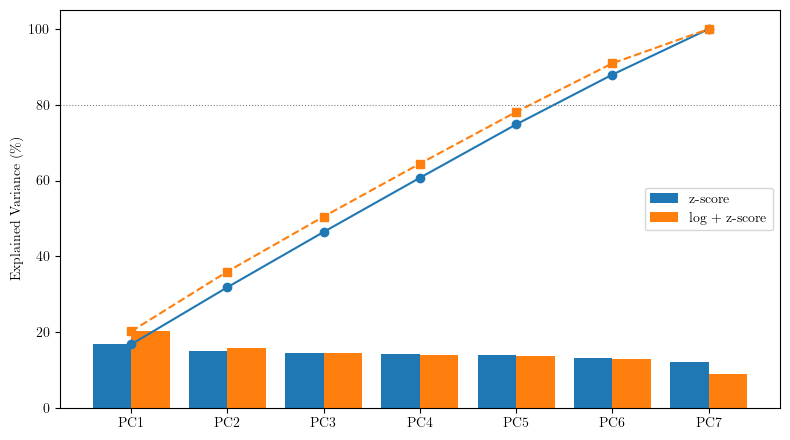

In [13]:
# 10c. Scree plot: explained variance per component and cumulative variance
x = np.arange(7)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - 0.2, evr["z-score"], 0.4, label="z-score", color="tab:blue")
ax.bar(x + 0.2, evr["log + z-score"], 0.4, label="log + z-score", color="tab:orange")
ax.plot(x, evr["z-score"].cumsum(), "o-", color="tab:blue")
ax.plot(x, evr["log + z-score"].cumsum(), "s--", color="tab:orange")
ax.axhline(80, color="gray", lw=0.8, ls=":")
ax.set_xticks(x); ax.set_xticklabels(pcs)
ax.set_ylabel(r"Explained Variance (\%)"); ax.set_ylim(0, 105); ax.legend(loc="center right")
plt.tight_layout()
plt.savefig("figures/pca_scree.png", dpi=300, bbox_inches="tight")
plt.show()

In [21]:
# LaTeX (pgfplots) version of the scree plot
def scree_to_latex(evr, path, colors):
    L = ["{%", r"\begin{tikzpicture}", r"\begin{axis}[",
         r"  width=\columnwidth, height=0.62\columnwidth,",
         r"  ymin=0, ymax=105, xtick=data, symbolic x coords={" + ",".join(evr.index) + "},",
         r"  enlarge x limits=0.08, ylabel={Explained Variance (\%)},",
         r"  tick label style={font=\scriptsize}, label style={font=\small},",
         r"  legend style={at={(0.98,0.55)}, anchor=east, font=\scriptsize}, legend cell align=left,",
         "]"]
    for (col, c), shift in zip(zip(evr.columns, colors), [-3.5, 3.5]):
        r, g, b = [int(round(x * 255)) for x in mpl.colors.to_rgb(c)]
        rgb = f"{{rgb,255:red,{r};green,{g};blue,{b}}}"
        bars = " ".join(f"({i},{v:.2f})" for i, v in evr[col].items())
        cum = " ".join(f"({i},{v:.2f})" for i, v in evr[col].cumsum().items())
        L.append(rf"\addplot[ybar, area legend, bar width=6pt, bar shift={shift}pt, fill={rgb}, draw=none] coordinates {{{bars}}};")
        L.append(r"\addlegendentry{" + col + "}")
        L.append(rf"\addplot[color={rgb}, mark=*, mark size=1.2pt, forget plot] coordinates {{{cum}}};")
    L.append(r"\draw[gray, dotted] ({rel axis cs:0,0} |- {axis cs:PC1,80}) -- ({rel axis cs:1,0} |- {axis cs:PC1,80});")
    L += [r"\end{axis}", r"\end{tikzpicture}%", "}"]
    with open(path, "w", encoding="utf-8") as f:
        f.write("\n".join(L))
    print("Saved:", path)

scree_to_latex(evr, "figures/pca_scree.tex", ["tab:blue", "tab:orange"])

Saved: figures/pca_scree.tex


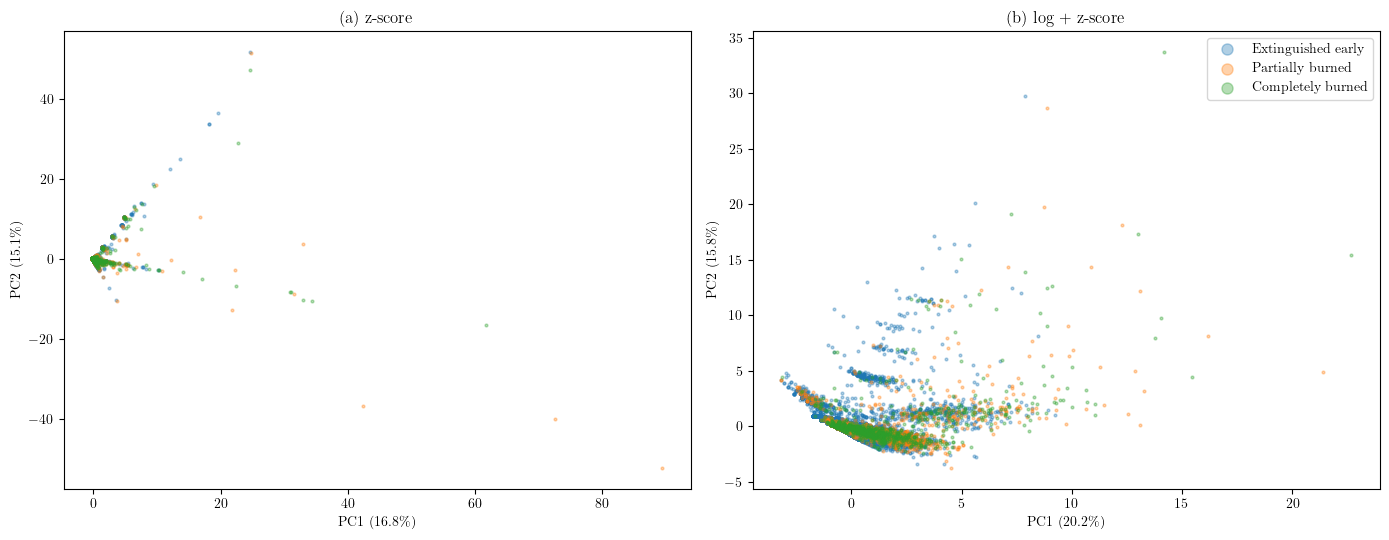

In [14]:
# 10d. Fires on the first two components, coloured by fire result
Z2, L2 = pca_z.transform(X_z)[:, :2], pca_log.transform(X_log)[:, :2]
colors = {"Extinguished early": "tab:blue", "Partially burned": "tab:orange", "Completely burned": "tab:green"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, P, p, title in [(axes[0], Z2, pca_z, "(a) z-score"), (axes[1], L2, pca_log, "(b) log + z-score")]:
    for r in result_order:
        m = (df_out["fire_result"] == r).values
        ax.scatter(P[m, 0], P[m, 1], s=4, alpha=0.35, color=colors[r], label=r)
    ev = p.explained_variance_ratio_ * 100
    ax.set_xlabel(rf"PC1 ({ev[0]:.1f}\%)"); ax.set_ylabel(rf"PC2 ({ev[1]:.1f}\%)"); ax.set_title(title)
axes[1].legend(loc="upper right", markerscale=4)
plt.tight_layout()
plt.savefig("figures/pca_2d.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
# 10e. Median PC1 / PC2 scores (log version) by fire result and region
df_out["PC1"], df_out["PC2"] = L2[:, 0], L2[:, 1]
print(df_out.groupby("fire_result", observed=True)[["PC1", "PC2"]].median().round(2))
print()
print(df_out.groupby("region")[["PC1", "PC2"]].median().round(2))
top = df_out[df_out["PC2"] > df_out["PC2"].quantile(0.99)]
print(f"\nTop 1% PC2: building fires {(top['fire_type'] == 'Building').mean() * 100:.0f}%, "
      f"urban {(top['region'] == 'Urban').mean() * 100:.0f}%")

                     PC1   PC2
fire_result                   
Extinguished early -0.27 -0.05
Partially burned    1.06 -0.27
Completely burned   0.76 -0.21

                   PC1   PC2
region                      
Outside province  1.77 -1.31
Rural             0.37 -0.46
Urban            -0.48  0.05

Top 1% PC2: building fires 66%, urban 78%


Districts: 30
Explained variance (%): [46.6 19.3 14.2 10.2  5.3  3.   1.5]
Cumulative (%): [ 46.6  65.9  80.1  90.2  95.5  98.5 100. ]
                    PC1   PC2
n_fires           -0.28 -0.15
median_arrival     0.46  0.20
damaged_pct        0.41  0.41
mean_water         0.26  0.33
rural_pct          0.50 -0.09
structure_pct     -0.41  0.48
casualties_per100 -0.24  0.65


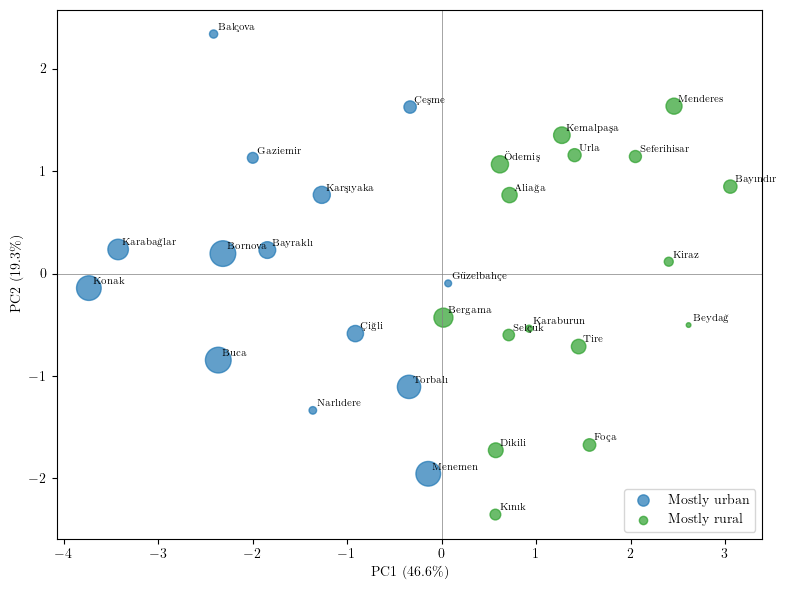

In [22]:
# 10f. PCA on district-level aggregates (same aggregates as the correlation step, districts with >= 30 fires)
dist = df_out.groupby("district").agg(
    n_fires        = ("fire_type", "size"),
    median_arrival = ("arrival_min", "median"),
    damaged_pct    = ("fire_severity", lambda s: (s > 0).mean() * 100),
    mean_water     = ("water_m3", "mean"),
    rural_pct      = ("region", lambda s: (s == "Rural").mean() * 100),
    structure_pct  = ("building_type", lambda s: (s != "Not applicable").mean() * 100))
dist["casualties_per100"] = (df_out.groupby("district")[["human_deaths", "human_injured"]]
                             .sum().sum(axis=1) / dist["n_fires"] * 100)
dist = dist[dist["n_fires"] >= 30]

pca_d = PCA().fit(StandardScaler().fit_transform(dist))
D2 = pca_d.transform(StandardScaler().fit_transform(dist))[:, :2]
print("Districts:", len(dist))
print("Explained variance (%):", (pca_d.explained_variance_ratio_ * 100).round(1))
print("Cumulative (%):", (pca_d.explained_variance_ratio_.cumsum() * 100).round(1))
print(pd.DataFrame(pca_d.components_[:2].T, index=dist.columns, columns=["PC1", "PC2"]).round(2))

# Turkish-aware names (same helpers as preprocessing.ipynb)
def tr_title(s):
    s = s.replace("I", "ı").replace("İ", "i").lower()
    return {"i": "İ", "ı": "I"}.get(s[0], s[0].upper()) + s[1:]
TEX_TR = {"ç": r"\c{c}", "Ç": r"\c{C}", "ğ": r"\u{g}", "Ğ": r"\u{G}", "ı": r"{\i}", "İ": r"\.{I}",
          "ö": r'\"{o}', "Ö": r'\"{O}', "ş": r"\c{s}", "Ş": r"\c{S}", "ü": r'\"{u}', "Ü": r'\"{U}'}
def tex_tr(s):
    return "".join(TEX_TR.get(ch, ch) for ch in s)

types = np.where(dist["rural_pct"] > 50, "Mostly rural", "Mostly urban")
palette = {"Mostly urban": "tab:blue", "Mostly rural": "tab:green"}
fig, ax = plt.subplots(figsize=(8, 6))
for t, c in palette.items():
    m = types == t
    ax.scatter(D2[m, 0], D2[m, 1], s=dist["n_fires"][m] / 8, color=c, alpha=0.7, label=t)
for (x, y), name in zip(D2, dist.index):
    ax.annotate(tex_tr(tr_title(name)), (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ev = pca_d.explained_variance_ratio_ * 100
ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel(rf"PC1 ({ev[0]:.1f}\%)"); ax.set_ylabel(rf"PC2 ({ev[1]:.1f}\%)")
ax.legend(loc="lower right", markerscale=0.6)
plt.tight_layout()
plt.savefig("figures/pca_district.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
# LaTeX (pgfplots) version of the district PCA figure
def district_pca_to_latex(D2, names, types, sizes, ev, path, palette):
    L = ["{%", r"\begin{tikzpicture}", r"\begin{axis}[",
         r"  width=\columnwidth, height=0.8\columnwidth,",
         rf"  xmax={D2[:, 0].max() + 1:.1f},",                               # room for the labels on the right
         rf"  xlabel={{PC1 ({ev[0]:.1f}\%)}}, ylabel={{PC2 ({ev[1]:.1f}\%)}},",
         r"  tick label style={font=\scriptsize}, label style={font=\small},",
         r"  legend style={at={(0.98,0.02)}, anchor=south east, font=\scriptsize}, legend cell align=left,",
         "]"]
    for label, color in palette.items():
        r, g, b = [int(round(x * 255)) for x in mpl.colors.to_rgb(color)]
        L.append(rf"\addlegendimage{{only marks, mark=*, color={{rgb,255:red,{r};green,{g};blue,{b}}}}}")
        L.append(r"\addlegendentry{" + label + "}")
    L.append(r"\draw[gray, very thin] (axis cs:0,\pgfkeysvalueof{/pgfplots/ymin}) -- (axis cs:0,\pgfkeysvalueof{/pgfplots/ymax});")
    L.append(r"\draw[gray, very thin] (axis cs:\pgfkeysvalueof{/pgfplots/xmin},0) -- (axis cs:\pgfkeysvalueof{/pgfplots/xmax},0);")
    below = {"Bornova", "Sel\\c{c}uk"}                                       # labels moved below to avoid overlap
    for (x, y), name, t, s in zip(D2, names, types, sizes):
        r, g, b = [int(round(c * 255)) for c in mpl.colors.to_rgb(palette[t])]
        L.append(rf"\addplot[only marks, mark=*, mark size={s:.1f}pt, color={{rgb,255:red,{r};green,{g};blue,{b}}}, "
                 rf"fill opacity=0.7, forget plot] coordinates {{({x:.3f},{y:.3f})}};")
        anchor = "north west" if name in below else "south west"
        L.append(rf"\node[font=\tiny, anchor={anchor}, inner sep=1pt] at (axis cs:{x:.3f},{y:.3f}) {{{name}}};")
    L += [r"\end{axis}", r"\end{tikzpicture}%", "}"]
    with open(path, "w", encoding="utf-8") as f:
        f.write("\n".join(L))
    print("Saved:", path)

sizes = 1 + 3 * np.sqrt(dist["n_fires"] / dist["n_fires"].max())     # marker size grows with the number of fires
district_pca_to_latex(D2, [tex_tr(tr_title(n)) for n in dist.index], types, sizes, ev,
                      "figures/pca_district.tex", palette)

Saved: figures/pca_district.tex


***11. Data Augmentation***


In [16]:
# 11a. Class distribution of the fire result
print(df_out["fire_result"].value_counts(sort=False))
print((df_out["fire_result"].value_counts(normalize=True, sort=False) * 100).round(1))

fire_result
Extinguished early    29349
Partially burned       1484
Completely burned      1012
Name: count, dtype: int64
fire_result
Extinguished early    92.2
Partially burned       4.7
Completely burned      3.2
Name: proportion, dtype: float64


In [17]:
# 11b. SMOTENC (SMOTE for numeric + categorical data), applied only to the training split
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTENC

# group rare fire types (< 1%) into "Other", same as the one-hot encoding step
counts = df_out["fire_type"].value_counts()
rare = counts[counts / len(df_out) < 0.01].index
df_out["fire_type_grouped"] = df_out["fire_type"].where(~df_out["fire_type"].isin(rare), "Other")

cat_cols = ["fire_type_grouped", "region"]
X = df_out[num + cat_cols].copy()
y = df_out["fire_result"].astype(str)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# log + z-score on the numeric attributes so that distances are comparable
sc = StandardScaler().fit(np.log1p(X_train[num]))
X_tr = X_train.copy()
X_tr[num] = sc.transform(np.log1p(X_train[num]))

smote = SMOTENC(categorical_features=[X_tr.columns.get_loc(c) for c in cat_cols], random_state=42)
X_res, y_res = smote.fit_resample(X_tr, y_train)

aug = pd.DataFrame({"Train": y_train.value_counts(),
                    "Train (SMOTENC)": y_res.value_counts(),
                    "Test": y_test.value_counts()}).loc[result_order]
aug.loc["Total"] = aug.sum()
print(aug)

                    Train  Train (SMOTENC)  Test
fire_result                                     
Extinguished early  23479            23479  5870
Partially burned     1187            23479   297
Completely burned     810            23479   202
Total               25476            70437  6369


In [18]:
# 11c. Check the synthetic records in original units
synth = X_res.iloc[len(X_tr):].copy()
synth[num] = np.expm1(sc.inverse_transform(synth[num]))
counts_cols = ["human_deaths", "human_injured", "animal_deaths"]
non_int = (synth[counts_cols] - synth[counts_cols].round()).abs() > 0.01
print("Synthetic records:", len(synth))
print(f"Share of synthetic records in the balanced training set: {len(synth) / len(X_res) * 100:.1f}%")
print("Synthetic records with a non-integer death/injury count:", non_int.any(axis=1).sum(),
      f"({non_int.any(axis=1).mean() * 100:.1f}%)")

Synthetic records: 44961
Share of synthetic records in the balanced training set: 63.8%
Synthetic records with a non-integer death/injury count: 1667 (3.7%)


**Note:** Augmentation is possible for this data set, and SMOTENC is the suitable method because the data have both numeric and categorical attributes. However, 64% of the balanced training set is synthetic and 3.7% of the synthetic records have non-integer death/injury counts, so the augmented data were **not** added to the main data set. It should only be used on the training split in the classification step (Section V), and compared with class weights.

***12. Comparison of the Preprocessing Results***

In [19]:
# 12. Effect of the outlier correction and the log transform on scaling
from sklearn.preprocessing import MinMaxScaler

def scaled_stats(data):
    zmax = ((data - data.mean()) / data.std(ddof=0)).max()
    mm_mean = pd.DataFrame(MinMaxScaler().fit_transform(data), columns=data.columns).mean()
    return zmax, mm_mean

z0, m0 = scaled_stats(df[num])                  # original (as in Table III)
z1, m1 = scaled_stats(df_out[num])              # after correcting the 5 records
z2, m2 = scaled_stats(np.log1p(df_out[num]))    # after log1p transform
comp = pd.DataFrame({"Max z (original)": z0, "Max z (corrected)": z1, "Max z (log1p)": z2,
                     "Min-Max mean (original)": m0, "Min-Max mean (log1p)": m2})
print(comp.round(3))

               Max z (original)  Max z (corrected)  Max z (log1p)  \
arrival_min              48.371             48.371          7.833   
water_m3                126.108            135.388         10.473   
foam_kg                 101.823            101.823         14.845   
dry_powder_kg            61.814             61.814         13.891   
human_deaths             87.506             87.506         58.416   
human_injured            57.572             57.572         27.841   
animal_deaths           173.967            173.967         51.699   

               Min-Max mean (original)  Min-Max mean (log1p)  
arrival_min                      0.023                 0.326  
water_m3                         0.000                 0.088  
foam_kg                          0.000                 0.009  
dry_powder_kg                    0.002                 0.011  
human_deaths                     0.000                 0.001  
human_injured                    0.001                 0.003  
animal

In [ ]:
# save the outlier-checked data (corrected water values + Isolation Forest flag) for the next sections
df_out.drop(columns=["PC1", "PC2", "fire_type_grouped"]).to_csv("outlier_checked_data.csv", index=False)
print(pd.read_csv("outlier_checked_data.csv").shape)

(31845, 19)


**Note:** Correcting the 5 implausible water values does not fix the scaling problem (max z of water even increases from 126.1 to 135.4), but the log1p transform reduces the max z of arrival time, water, foam and dry powder to 7.8–14.8. Casualty attributes stay skewed because they are zero in more than 99% of fires. For distance-based methods (e.g. clustering) the log + z-score version of the attributes should be used; for descriptive analysis the original units are kept. The file `outlier_checked_data.csv` contains the corrected water values and the `iso_outlier` flag.